# 通常FDM: 直接法 vs 反復法 (CG) の性能比較

2次元Poisson方程式 $-\Delta u = f$ を FDM で離散化し，
$(A u = b)$ を以下の2つの方法で解く：

- **直接法**: `A \ b`（LU分解）$O(N^3)$
- **反復法 (CG)**: $A$ がスパースなので行列ベクトル積が $O(N)$ → CG 全体 $O(N \times \text{iter})$

$N = Nx \times Ny$ を変えながら計算時間・残差・イテレーション数を比較する。

In [1]:
using LinearAlgebra
using SparseArrays
using IterativeSolvers
using Plots
using Statistics

In [2]:
# FDM行列をスパースで構築
function build_FDM_sparse(Nx, Ny, dx)
    N = Nx * Ny
    index(i, j) = i + (j - 1) * Nx
    rows, cols, vals = Int[], Int[], Float64[]

    for j in 1:Ny, i in 1:Nx
        k = index(i, j)
        push!(rows, k); push!(cols, k); push!(vals, -4.0 / dx^2)
        if i > 1;  push!(rows, k); push!(cols, index(i-1,j)); push!(vals, 1.0/dx^2); end
        if i < Nx; push!(rows, k); push!(cols, index(i+1,j)); push!(vals, 1.0/dx^2); end
        if j > 1;  push!(rows, k); push!(cols, index(i,j-1)); push!(vals, 1.0/dx^2); end
        if j < Ny; push!(rows, k); push!(cols, index(i,j+1)); push!(vals, 1.0/dx^2); end
    end
    return sparse(rows, cols, vals, N, N)
end

# 右辺・真の解
f_func(x, y)  = -sin(π*x) * sin(π*y)
u_exact(x, y) =  sin(π*x) * sin(π*y) / (2π^2)

u_exact (generic function with 1 method)

In [5]:
# グリッドサイズのリスト (Nx = Ny)
grid_sizes = [10, 20, 50, 100, 200, 500, 1000]

results = []

for Nx in grid_sizes
    Ny = Nx
    N  = Nx * Ny
    Lx = 1.0
    dx = Lx / (Nx + 1)

    x = range(dx, step=dx, length=Nx)
    y = range(dx, step=dx, length=Ny)

    # スパース行列・右辺・真の解
    A_sp   = build_FDM_sparse(Nx, Ny, dx)
    b_vec  = [f_func(xi, yj)  for yj in y for xi in x]
    u_true = [u_exact(xi, yj) for yj in y for xi in x]

    # ===== 直接法: LU =====
    t_direct = @elapsed begin
        u_direct = A_sp \ b_vec
    end
    mse_direct = mean((u_direct .- u_true).^2)
    res_direct = norm(A_sp * u_direct - b_vec) / norm(b_vec)

    # ===== 反復法: CG =====
    # A は負定値なので -A (正定値) で解いて符号を戻す
    t_cg = @elapsed begin
        u_cg, hist = cg(-A_sp, -b_vec; log=true, maxiter=10N, reltol=1e-10)
    end
    mse_cg    = mean((u_cg .- u_true).^2)
    res_cg    = norm(A_sp * u_cg - b_vec) / norm(b_vec)
    n_iter_cg = hist.iters

    push!(results, (
        N=N, Nx=Nx,
        t_direct=t_direct, t_cg=t_cg,
        mse_direct=mse_direct, mse_cg=mse_cg,
        res_direct=res_direct, res_cg=res_cg,
        n_iter_cg=n_iter_cg
    ))

    println("Nx=$Nx (N=$N):")
    println("  Direct: $(round(t_direct,sigdigits=3))s  MSE=$(round(mse_direct,sigdigits=3))  res=$(round(res_direct,sigdigits=3))")
    println("  CG:     $(round(t_cg,sigdigits=3))s  MSE=$(round(mse_cg,sigdigits=3))  res=$(round(res_cg,sigdigits=3))  iter=$n_iter_cg")
end

Nx=10 (N=100):
  Direct: 0.000216s  MSE=3.62e-8  res=3.54e-15
  CG:     2.35e-5s  MSE=3.62e-8  res=4.49e-15  iter=1
Nx=20 (N=400):
  Direct: 0.000521s  MSE=2.47e-9  res=1.24e-14
  CG:     9.5e-6s  MSE=2.47e-9  res=1.3e-14  iter=1
Nx=50 (N=2500):
  Direct: 0.0045s  MSE=6.68e-11  res=6.98e-14
  CG:     4.24e-5s  MSE=6.68e-11  res=8.08e-14  iter=1
Nx=100 (N=10000):
  Direct: 0.0162s  MSE=4.26e-12  res=3.12e-13
  CG:     0.000158s  MSE=4.26e-12  res=2.74e-13  iter=1
Nx=200 (N=40000):
  Direct: 0.0619s  MSE=2.69e-13  res=1.23e-12
  CG:     0.000612s  MSE=2.69e-13  res=1.18e-12  iter=1
Nx=500 (N=250000):
  Direct: 0.605s  MSE=6.92e-15  res=8.45e-12
  CG:     0.00422s  MSE=6.92e-15  res=8.03e-12  iter=1
Nx=1000 (N=1000000):
  Direct: 3.36s  MSE=4.33e-16  res=3.61e-11
  CG:     0.0183s  MSE=4.33e-16  res=3.01e-11  iter=1


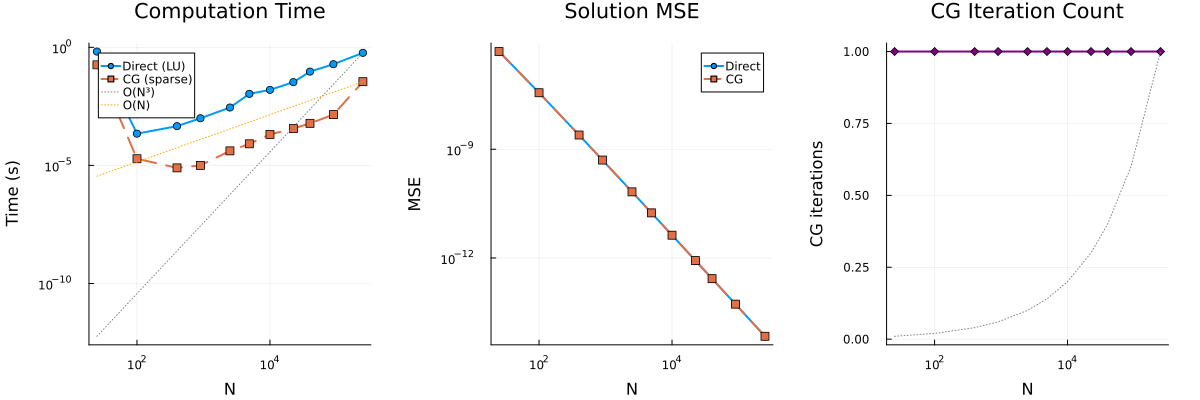

Saved: fdm_direct_vs_cg.png


In [4]:
Ns        = [r.N        for r in results]
t_dir     = [r.t_direct for r in results]
t_cg_v    = [r.t_cg     for r in results]
mse_dir   = [r.mse_direct for r in results]
mse_cg_v  = [r.mse_cg     for r in results]
n_iters   = [r.n_iter_cg  for r in results]

# 計算時間
p1 = plot(Ns, t_dir;
    marker=:circle, lw=2, label="Direct (LU)",
    xlabel="N", ylabel="Time (s)", title="Computation Time",
    yscale=:log10, xscale=:log10, legend=:topleft)
plot!(p1, Ns, t_cg_v;
    marker=:square, lw=2, ls=:dash, label="CG (sparse)")
c3 = t_dir[end] / Ns[end]^3
c1 = t_cg_v[end] / Ns[end]
plot!(p1, Ns, c3 .* Ns.^3; lw=1, ls=:dot, color=:gray,   label="O(N³)")
plot!(p1, Ns, c1 .* Ns;    lw=1, ls=:dot, color=:orange, label="O(N)")

# MSE
p2 = plot(Ns, mse_dir;
    marker=:circle, lw=2, label="Direct",
    xlabel="N", ylabel="MSE", title="Solution MSE",
    yscale=:log10, xscale=:log10, legend=:topright)
plot!(p2, Ns, mse_cg_v;
    marker=:square, lw=2, ls=:dash, label="CG")

# CGイテレーション数
p3 = plot(Ns, n_iters;
    marker=:diamond, lw=2, color=:purple,
    xlabel="N", ylabel="CG iterations", title="CG Iteration Count",
    xscale=:log10, legend=false)
# O(sqrt(N)) 参照線 (理論的な CG の収束レート)
c_sq = n_iters[end] / sqrt(Ns[end])
plot!(p3, Ns, c_sq .* sqrt.(Ns); lw=1, ls=:dot, color=:gray, label="O(√N)")

p_all = plot(p1, p2, p3; layout=(1,3), size=(1200, 400), margin=6Plots.mm)
display(p_all)
savefig(p_all, "fdm_direct_vs_cg.png")
println("Saved: fdm_direct_vs_cg.png")